In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline


In [6]:
price_raw_df = pd.read_csv("C:/Users/Winifred/Ironhack/Part time program/Labs/Statistics Lab/Lab EDA-Univariate/amz_uk_price_prediction_dataset.csv")

In [7]:
price_raw_df.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [8]:
price_raw_df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [10]:
price_raw_df.shape

(2443651, 9)

In [13]:
price_raw_df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

In [14]:
price_raw_df.isnull().sum().sort_values(ascending=False)

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [19]:
# Frequency table for 'category'
frequency_table = price_raw_df['category'].value_counts()
print(frequency_table)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64


In [22]:
top_5_categories = price_raw_df['category'].value_counts().head(5)
print(top_5_categories)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


The frequency table presents the top five most listed product categories on Amazon UK, along with the number of products in each category. This helps identify which product categories are the most common in the dataset.

([0, 1, 2, 3, 4],
 [Text(0, 0, 'Sports & Outdoors'),
  Text(1, 0, 'Beauty'),
  Text(2, 0, 'Handmade Clothing, Shoes & Accessories'),
  Text(3, 0, 'Bath & Body'),
  Text(4, 0, 'Birthday Gifts')])

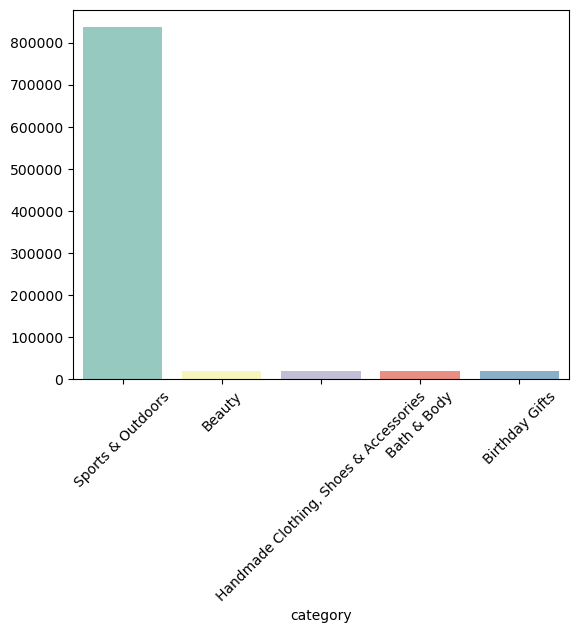

In [26]:
# Plotting a bar chart using the values from the frequency table, with colors sourced from the "Set3" palette
sns.barplot(x=top_5_categories.index, y=top_5_categories.values,hue=top_5_categories.index, palette="Set3"); plt.xticks(rotation=45)

<Axes: ylabel='count'>

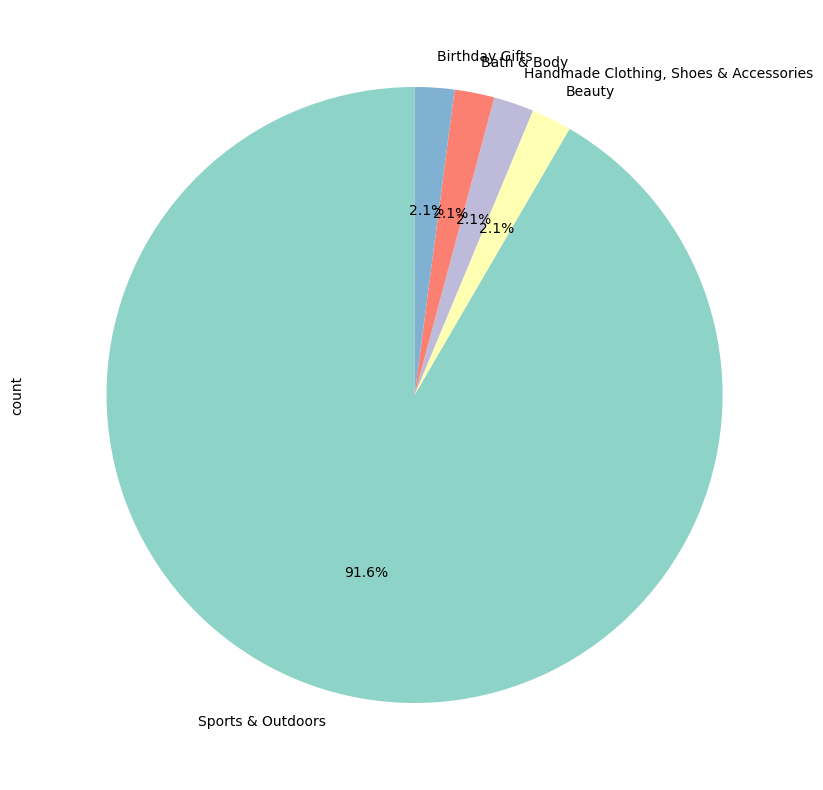

In [30]:
plt.figure(figsize=(10, 10))
top_5_categories.plot.pie(autopct='%1.1f%%', startangle=90, colors=sns.color_palette("Set3"))

In [32]:
mean_price = price_raw_df['price'].mean()
median_price = price_raw_df['price'].median()
mode_price = price_raw_df['price'].mode()

print("Mean:", mean_price)
print("Median:", median_price)
print("Mode:")
print(mode_price)

Mean: 89.24380943923661
Median: 19.09
Mode:
0    9.99
Name: price, dtype: float64


The average (mean) price of products listed on Amazon UK is £89.24, while the median price is £19.09 and the most common price (mode) is £9.99. The mean is considerably higher than both the median and the mode, suggesting that a small number of expensive products increase the average price. Most products are listed at much lower prices, with £9.99 being the most common price point.

In [41]:
variance_price = price_raw_df['price'].var()
std_dev_price = price_raw_df['price'].std()
min_price = price_raw_df['price'].min()
max_price = price_raw_df['price'].max()
range_price = max_price - min_price
quantiles_price = price_raw_df['price'].quantile([0.25, 0.5, 0.75])
iqr = quantiles_price[0.75] - quantiles_price[0.25]

print(f"Variance is {variance_price}")
print(f"Standard deviation is {std_dev_price}")
print(f"Minimum price is {min_price}")
print(f"Maximum price is {max_price}")
print(f"Range is {range_price}")
print(f"Interquartile range (IQR) is {iqr}")

Variance is 119445.48532256528
Standard deviation is 345.60886175352226
Minimum price is 0.0
Maximum price is 100000.0
Range is 100000.0
Interquartile range (IQR) is 36.0


The product prices exhibit a large amount of variation. The variance is 119,445.49 and the standard deviation is £345.61, indicating that prices are widely spread around the mean. The price range is £100,000, from £0.00 to £100,000.00, which suggests the presence of extreme values. However, the interquartile range (IQR) is only £36.00, meaning that the middle 50% of product prices lie between £9.99 and £45.99. This indicates that although most products are relatively low-priced, a small number of very expensive products create a significant spread in the data.

<Axes: xlabel='price', ylabel='Count'>

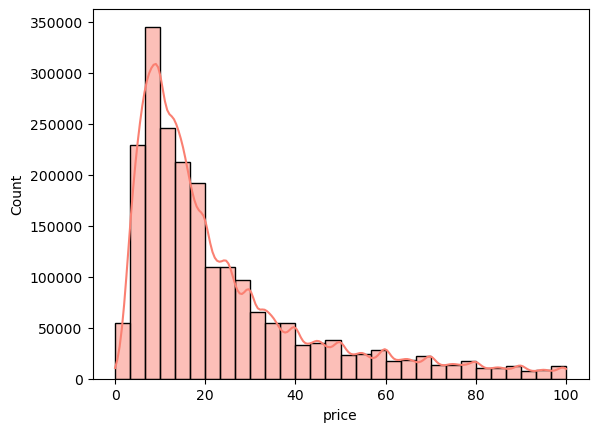

In [45]:
price_subset = price_raw_df[price_raw_df['price'] <= 100]

sns.histplot(price_subset['price'], kde=True, bins=30, color="salmon")

The histogram shows that most products are concentrated within the lower price ranges. Due to a small number of extremely expensive products, the full price distribution is difficult to interpret. Therefore, the analysis focuses on products priced below £100, which provides a clearer view of the typical pricing patterns among most products.

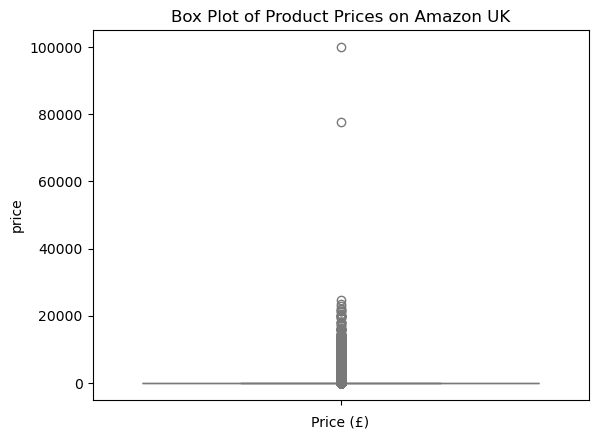

In [50]:
sns.boxplot(data=price_raw_df['price'], color="lightblue")

plt.title("Box Plot of Product Prices on Amazon UK")
plt.xlabel("Price (£)")
plt.show()

The box plot shows the spread of customer ratings for products on Amazon UK. The box represents the middle 50% of ratings, while the line inside the box represents the median rating. A narrow box indicates that most customer ratings are clustered within a similar range, suggesting consistent customer feedback. Any points outside the whiskers represent potential outliers, where products received unusually high or low ratings compared with the majority.

In [52]:
price_raw_df['stars'].value_counts()

stars
0.0    1225641
4.5     151577
4.6     136995
4.4     136165
5.0     128492
4.3     112564
4.7      94566
4.2      86871
4.0      66089
4.1      65115
4.8      41858
3.9      36555
3.8      27876
3.7      21137
3.6      16219
3.5      14673
3.0      12819
4.9      11081
3.4      10355
1.0       8484
3.3       8269
3.2       5771
3.1       4679
2.0       3901
2.9       3341
2.8       2306
2.7       2104
2.5       2103
2.6       1579
2.4       1060
2.3        734
2.2        602
2.1        540
1.5        404
1.9        300
1.8        249
1.7        177
1.4        149
1.6        147
1.3         78
1.2         23
1.1          3
Name: count, dtype: int64

In [53]:
stars_clean = price_raw_df[price_raw_df['stars'] > 0]['stars']

In [54]:
mean_stars = stars_clean.mean()
median_stars = stars_clean.median()
mode_stars = stars_clean.mode()[0]

print(f"Mean rating is {mean_stars}")
print(f"Median rating is {median_stars}")
print(f"Mode rating is {mode_stars}")

Mean rating is 4.319160762226911
Median rating is 4.4
Mode rating is 4.5


The average customer rating is 4.32 stars, with a median rating of 4.40 stars and the most common rating being 4.50 stars. Since the mean, median, and mode are very close to each other, this suggests that customer ratings are generally consistent and concentrated around the higher end of the rating scale. Overall, customers tend to rate products positively, with most products receiving ratings above 4 stars.



In [55]:
variance_stars = stars_clean.var()
std_stars = stars_clean.std()

q1_stars = stars_clean.quantile(0.25)
q3_stars = stars_clean.quantile(0.75)

iqr_stars = q3_stars - q1_stars

print(f"Variance is {variance_stars}")
print(f"Standard deviation is {std_stars}")
print(f"Interquartile range (IQR) is {iqr_stars}")

Variance is 0.3083433752380519
Standard deviation is 0.5552867504614637
Interquartile range (IQR) is 0.5


The customer ratings show relatively low variation. The standard deviation of 0.56 stars indicates that most ratings are close to the average rating of 4.32 stars. The interquartile range of 0.5 stars shows that the middle 50% of ratings are concentrated within a narrow range, suggesting that customer feedback is generally consistent. Overall, product ratings do not show a wide spread, with most customers giving similar ratings.

In [56]:
skewness_stars = stars_clean.skew()
kurtosis_stars = stars_clean.kurt()

print(f"Skewness is {skewness_stars}")
print(f"Kurtosis is {kurtosis_stars}")

Skewness is -2.379568112212799
Kurtosis is 9.78193769066435


The ratings are not normally distributed. They are heavily concentrated towards higher ratings, with most products receiving positive customer feedback. The negative skewness confirms that lower ratings are less common and form the tail of the distribution.

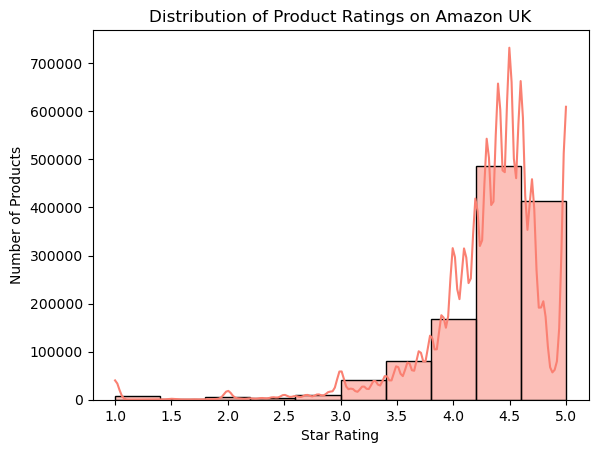

In [58]:
sns.histplot(stars_clean, kde=True, bins=10, color="salmon")
plt.title("Distribution of Product Ratings on Amazon UK")
plt.xlabel("Star Rating")
plt.ylabel("Number of Products")
plt.show()

The histogram shows that customer ratings are concentrated towards the higher end of the scale. The most common rating appears to be around 4.5 stars, indicating that highly rated products dominate the dataset. The distribution has a longer tail towards lower ratings, which is consistent with the negative skewness observed earlier. Overall, customers tend to provide positive ratings for products listed on Amazon UK.